# 04 — Feature Selection: Rain in Australia

**Proyek Akhir Data Science 2026/2027**  
**Metode tahap berikutnya:** Gaussian Naive Bayes dan Random Forest  
**Tahap CRISP-DM:** Data Preparation — Feature Selection (lanjutan `03_Data_Cleaning_Preprocessing.ipynb`)

### Tujuan notebook

1. Menilai **kelengkapan fitur** dan keterkaitannya dengan `RainTomorrow` menggunakan **data training saja**.
2. Menemukan **redundansi** antarfitur numerik dan mempertimbangkan makna meteorologinya.
3. Menetapkan daftar fitur **dipakai/dibuang beserta alasan yang bisa dipresentasikan**.
4. Membandingkan jumlah fitur sebelum/sesudah seleksi dan menyiapkan data untuk tahap Modeling.
5. Menyimpan konfigurasi fitur yang dipilih, agar tahap `05_Modeling.ipynb` konsisten.

> **Pencegahan data leakage:** semua keputusan pemilihan fitur menggunakan training **tanpa mengakses label test**. Ini bukan pelatihan atau evaluasi model. Metode seleksi masih perlu dikonfirmasi dalam validasi data training saat Modeling.

> **Data asli aman:** `weatherAUS.csv` hanya dibaca. CSV tidak ditimpa. Notebook dapat dijalankan sendiri tanpa mewarisi variabel kernel dari notebook 03.

## 1. Persiapan environment

Gunakan kernel `project_ds` yang sama dengan notebook 02–03. Pastikan tersedia `pandas`, `numpy`, `matplotlib`, dan `scikit-learn` (versi 1.2 atau lebih baru).

Jika muncul `ModuleNotFoundError`, gunakan `%pip install pandas numpy matplotlib scikit-learn` pada sel baru, kemudian **Restart Kernel** dan jalankan ulang.

In [9]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
MISSING_THRESHOLD = 0.40     # Ambang seleksi yang ditetapkan di muka (>= 40% missing di TRAIN)
CORRELATION_THRESHOLD = 0.95 # Ambang untuk meninjau fitur sangat redundan
MI_SAMPLE_LIMIT = 20_000     # Subset training untuk mempercepat perhitungan MI

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Aturan missing >=", MISSING_THRESHOLD, "; korelasi |r| >=", CORRELATION_THRESHOLD)

Python: 3.13.15
Pandas: 3.0.5
Scikit-learn: 1.9.0
Aturan missing >= 0.4 ; korelasi |r| >= 0.95


## 2. Membaca data dan mereplikasi Cleaning serta Train/Test Split tahap 03

Aturan yang sama dengan `03_Data_Cleaning_Preprocessing.ipynb`:

- Hapus duplikasi identik, tanggal tidak valid, dan baris target kosong/tidak valid.
- Ubah nilai numerik yang jelas tidak valid menjadi `NaN`.
- Buang `RISK_MM` bila ada, karena dapat membocorkan target.
- Bagi berdasarkan **80% tanggal unik historis**, dengan **purge gap 1 hari** untuk mencegah target training menyentuh awal test.

Bagian ini hanya membuat salinan di memori, **tidak memodifikasi CSV asli**.

In [10]:
candidate_paths = [Path("weatherAUS.csv"), Path("data/weatherAUS.csv")]
dataset_path = next((p for p in candidate_paths if p.is_file()), None)
if dataset_path is None:
    raise FileNotFoundError("Simpan weatherAUS.csv di samping notebook atau data/weatherAUS.csv")

df_raw = pd.read_csv(dataset_path, low_memory=False)
required = {"Date", "Location", "RainTomorrow"}
if required - set(df_raw.columns):
    raise ValueError("Kolom wajib tidak ditemukan: " + str(sorted(required - set(df_raw.columns))))

df_clean = df_raw.drop_duplicates().copy()
df_clean["Date"] = pd.to_datetime(df_clean["Date"], errors="coerce")
df_clean = df_clean.dropna(subset=["Date"]).copy()
df_clean = df_clean.loc[df_clean["RainTomorrow"].isin(["Yes", "No"])].copy()

for c in ["Rainfall", "Evaporation", "Sunshine", "WindGustSpeed", "WindSpeed9am", "WindSpeed3pm"]:
    if c in df_clean:
        invalid = df_clean[c].notna() & (df_clean[c] < 0)
        df_clean.loc[invalid, c] = np.nan
for c in ["Humidity9am", "Humidity3pm"]:
    if c in df_clean:
        invalid = df_clean[c].notna() & ~df_clean[c].between(0, 100)
        df_clean.loc[invalid, c] = np.nan
leakage_cols = [c for c in ["RISK_MM"] if c in df_clean.columns]
df_clean = df_clean.drop(columns=leakage_cols)

raw_dates = pd.to_datetime(df_raw["Date"], errors="coerce").dropna()
unique_dates = pd.Series(raw_dates.unique()).sort_values().reset_index(drop=True)
if len(unique_dates) < 10:
    raise ValueError("Tidak cukup tanggal unik untuk train/test split")
cutoff = pd.Timestamp(unique_dates.iloc[int(len(unique_dates) * .80)])
purge_date = cutoff - pd.Timedelta(days=1)
train_df = df_clean.loc[df_clean["Date"] < purge_date].copy()
test_df = df_clean.loc[df_clean["Date"] >= cutoff].copy()
purged_df = df_clean.loc[(df_clean["Date"] >= purge_date) & (df_clean["Date"] < cutoff)].copy()
if train_df.empty or test_df.empty:
    raise ValueError("Data training atau testing kosong")
assert train_df["Date"].max() < test_df["Date"].min()

feature_columns = [c for c in train_df.columns if c not in {"Date", "RainTomorrow"}]
X_train = train_df[feature_columns].copy()
X_test = test_df[feature_columns].copy()
y_train = train_df["RainTomorrow"].map({"No": 0, "Yes": 1}).astype(int)
# Label testing SENGAJA tidak digunakan untuk melakukan feature selection.

print("Dataset:", dataset_path.resolve())
print("Cutoff testing:", cutoff.date(), "| tanggal terakhir train:", train_df['Date'].max().date())
print("Jumlah train:", len(X_train), "| test:", len(X_test), "| purge gap:", len(purged_df))
print("Jumlah fitur kandidat asli:", len(feature_columns))
print("Distribusi label TRAIN:")
display(y_train.value_counts().rename(index={0:"No",1:"Yes"}).to_frame("Jumlah"))

Dataset: D:\Lahar V2\Project\Project Akhir Data Science\weatherAUS.csv
Cutoff testing: 2015-08-08 | tanggal terakhir train: 2015-08-06
Jumlah train: 109254 | test: 32891 | purge gap: 48
Jumlah fitur kandidat asli: 21
Distribusi label TRAIN:


,Jumlah
RainTomorrow,
No,84594
Yes,24660


## 3. Audit fitur **training**: missing value, tipe data, dan jumlah nilai unik

Fitur dengan missing tinggi berpotensi menambah ketidakpastian imputasi. Untuk **seleksi awal yang transparan**, kita mengusulkan membuang fitur dengan proporsi missing **≥ 40% pada training**. Angka 40% adalah **aturan praktis yang dipilih sebelum melihat hasil test**, bukan batas ilmiah universal; pengaruhnya perlu diuji pada validasi training.

Fitur berkorelasi rendah terhadap target **tidak langsung dibuang**, karena interaksi/nonlinearitas mungkin tetap berguna untuk Random Forest.

,Fitur,Tipe,Missing TRAIN,Missing TRAIN (%),Unik non-null,Calon drop: missing >= 40%
0,Sunshine,float64,46123,42.22,144,True
1,Evaporation,float64,42139,38.57,320,False
2,Cloud3pm,float64,40650,37.21,10,False
3,Cloud9am,float64,39616,36.26,10,False
4,Pressure9am,float64,10502,9.61,535,False
5,Pressure3pm,float64,10466,9.58,533,False
6,WindDir9am,str,8144,7.45,16,False
7,WindGustDir,str,7488,6.85,16,False
8,WindGustSpeed,float64,7445,6.81,67,False
9,WindDir3pm,str,2221,2.03,16,False


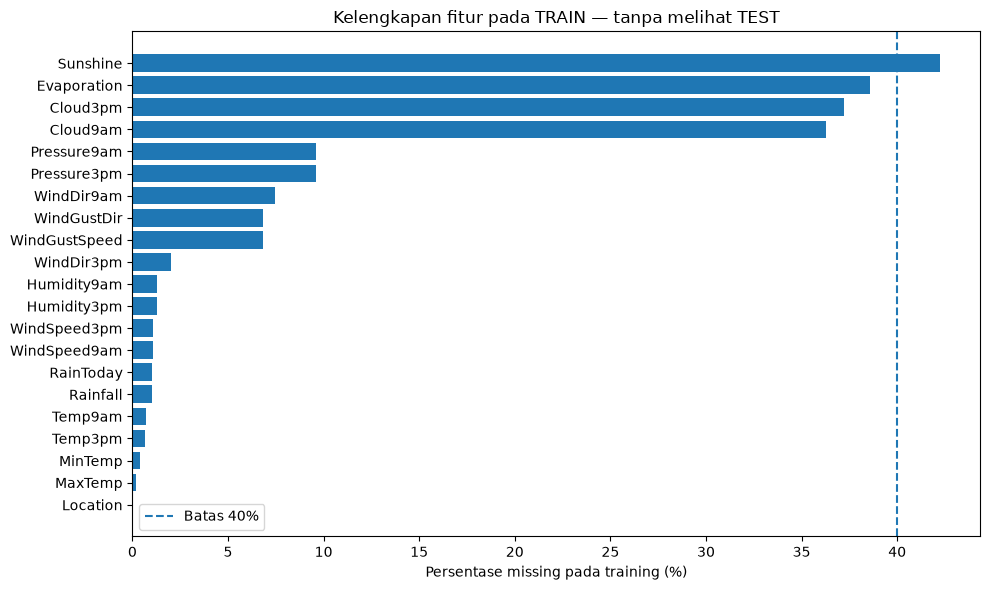

In [11]:
feature_audit = pd.DataFrame({
    "Fitur": X_train.columns,
    "Tipe": X_train.dtypes.astype(str).values,
    "Missing TRAIN": X_train.isna().sum().values.astype(int),
    "Missing TRAIN (%)": (X_train.isna().mean() * 100).round(2).values,
    "Unik non-null": X_train.nunique(dropna=True).values.astype(int),
}).sort_values(["Missing TRAIN (%)", "Fitur"], ascending=[False, True]).reset_index(drop=True)
feature_audit["Calon drop: missing >= 40%"] = feature_audit["Missing TRAIN (%)"] >= MISSING_THRESHOLD * 100

display(feature_audit)

fig, ax = plt.subplots(figsize=(10, 6))
plot_data = feature_audit.sort_values("Missing TRAIN (%)", ascending=True)
ax.barh(plot_data["Fitur"], plot_data["Missing TRAIN (%)"])
ax.axvline(MISSING_THRESHOLD * 100, linestyle="--", label=f"Batas {MISSING_THRESHOLD:.0%}")
ax.set_xlabel("Persentase missing pada training (%)")
ax.set_title("Kelengkapan fitur pada TRAIN — tanpa melihat TEST")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Hubungan fitur dengan target berdasarkan TRAIN: Mutual Information (MI)

**Mutual Information** mengukur besarnya informasi statistik fitur terhadap label dalam subset training (skor lebih besar = asosiasi terdeteksi lebih kuat, tetapi **bukan sebab-akibat**). Untuk efisiensi, evaluasi dilakukan pada sampel acak tetap, maksimal 20.000 baris training. Sampel **tidak berisi baris testing**.

- Fitur numerik: median diestimasi pada sampel training tersebut untuk pengukuran MI.
- Fitur kategorikal: modus dan kode kategori hanya untuk menghitung MI (bukan skema encoding final).
- Skor MI bukan ukuran kontribusi fitur pada model yang sudah dilatih; seleksi final akan diperiksa lewat validasi pada tahap Modeling.
- Hasil MI bisa bervariasi menurut sampling, terutama fitur dengan kategori banyak.

Ukuran sampel training untuk MI: 20000


,Fitur,MI (TRAIN saja)
0,Humidity3pm,0.11561
1,Sunshine,0.06338
2,Cloud3pm,0.06015
3,Rainfall,0.05651
4,RainToday,0.04350
5,Cloud9am,0.04182
6,Humidity9am,0.04117
7,Pressure9am,0.02617
8,WindGustSpeed,0.02568
9,Temp3pm,0.02239


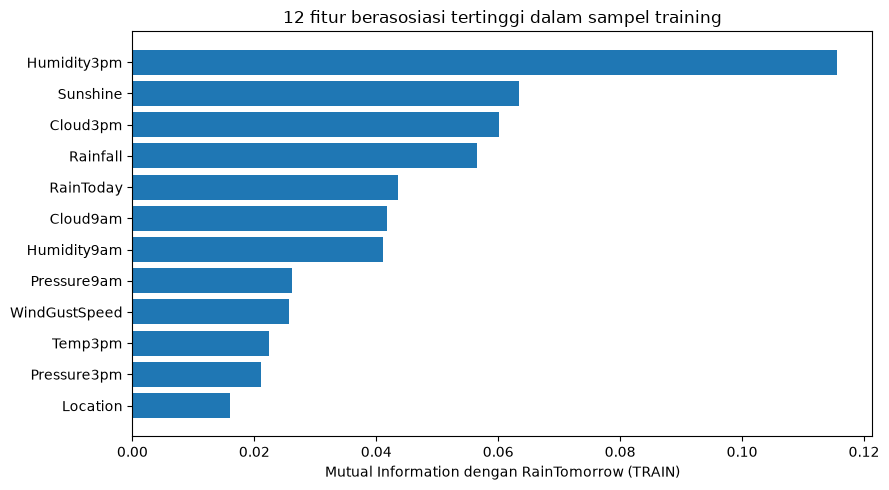

In [12]:
mi_sample = X_train.sample(n=min(MI_SAMPLE_LIMIT, len(X_train)), random_state=RANDOM_STATE)
y_mi = y_train.loc[mi_sample.index]
num_cols = mi_sample.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in mi_sample.columns if c not in num_cols]

arrays = []
if num_cols:
    mi_num_imputer = SimpleImputer(strategy="median", keep_empty_features=True)
    arrays.append(mi_num_imputer.fit_transform(mi_sample[num_cols]).astype(float))
if cat_cols:
    mi_cat_imputer = SimpleImputer(strategy="most_frequent", keep_empty_features=True)
    cat_values = mi_cat_imputer.fit_transform(mi_sample[cat_cols]).astype(str)
    arrays.append(OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit_transform(cat_values))
mi_matrix = np.column_stack(arrays)
mi_discrete = np.array([False] * len(num_cols) + [True] * len(cat_cols), dtype=bool)
mi_columns = num_cols + cat_cols
mi_scores = mutual_info_classif(mi_matrix, y_mi.to_numpy(), discrete_features=mi_discrete,
                                random_state=RANDOM_STATE, n_neighbors=3)
mi_table = pd.DataFrame({"Fitur": mi_columns, "MI (TRAIN saja)": mi_scores}).sort_values(
    "MI (TRAIN saja)", ascending=False).reset_index(drop=True)
print("Ukuran sampel training untuk MI:", len(mi_sample))
display(mi_table.round(5))

fig, ax = plt.subplots(figsize=(9, 5))
show_mi = mi_table.head(12).sort_values("MI (TRAIN saja)")
ax.barh(show_mi["Fitur"], show_mi["MI (TRAIN saja)"])
ax.set_xlabel("Mutual Information dengan RainTomorrow (TRAIN)")
ax.set_title("12 fitur berasosiasi tertinggi dalam sampel training")
plt.tight_layout()
plt.show()

## 5. Korelasi antarfitur numerik (TRAIN saja)

Korelasi Pearson dengan nilai absolut **≥ 0,95** menandai pasangan fitur yang **perlu ditinjau karena berpotensi redundan**. Ambang ini adalah aturan eksploratif, **bukan kewajiban menghapus salah satu fitur dari setiap pasangan**.

Dalam dataset yang dianalisis, terdapat dua pasangan menonjol (angka akhir mengikuti hasil eksekusi di bawah):

- **`Pressure9am` — `Pressure3pm`**: kedua variabel mengukur tekanan udara pada waktu berbeda. Untuk **baseline sederhana**, notebook mempertahankan `Pressure3pm` karena diukur lebih dekat ke hari berikutnya dan mengeluarkan `Pressure9am`. **Ini belum membuktikan `Pressure3pm` lebih informatif**. Justru perubahan tekanan pagi–sore berpotensi mengandung sinyal yang hilang jika `Pressure9am` dibuang.
- **`MaxTemp` — `Temp3pm`**: keduanya juga berkorelasi sangat tinggi. Namun, `MaxTemp` adalah **suhu maksimum harian**, sedangkan `Temp3pm` merupakan **suhu pada pengamatan sore**; informasi waktunya tidak persis sama. Untuk baseline, **keduanya tetap dipertahankan**, agar kemungkinan efek perbedaan waktu tidak dihilangkan sebelum divalidasi.

**Mengapa dua pasangan diperlakukan berbeda?** Ini adalah **keputusan rancangan baseline yang eksplisit, bukan aturan statistik otomatis**. Pasangan tekanan disederhanakan terlebih dahulu; pasangan suhu dipertahankan untuk eksperimen awal. Konsistensi dan manfaat dari kedua pilihan harus diuji dengan **validasi kronologis pada training saja**, misalnya membandingkan model dengan/ tanpa `Pressure9am`, dan dengan/ tanpa salah satu fitur suhu. **Testing tidak digunakan untuk mengambil keputusan ini.**


Pasangan dengan |r| >= 0.95


,Fitur A,Fitur B,Pearson r TRAIN
0,MaxTemp,Temp3pm,0.9846
1,Pressure9am,Pressure3pm,0.9621


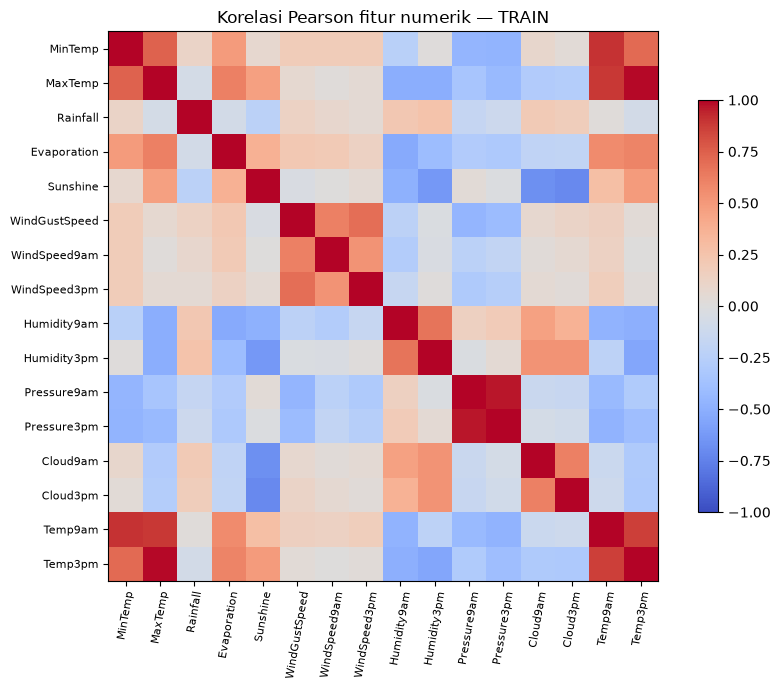

In [13]:
numeric_train = X_train.select_dtypes(include="number")
corr = numeric_train.corr(numeric_only=True)
strong_pairs = []
for i, a in enumerate(corr.columns):
    for b in corr.columns[i+1:]:
        r = corr.at[a, b]
        if pd.notna(r) and abs(r) >= CORRELATION_THRESHOLD:
            strong_pairs.append({"Fitur A": a, "Fitur B": b, "Pearson r TRAIN": round(float(r), 4)})
strong_corr_table = pd.DataFrame(strong_pairs, columns=["Fitur A", "Fitur B", "Pearson r TRAIN"])
print("Pasangan dengan |r| >=", CORRELATION_THRESHOLD)
display(strong_corr_table if len(strong_corr_table) else pd.DataFrame({"Temuan":["Tidak ada pasangan yang mencapai ambang korelasi."]}))

fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(np.arange(len(corr.columns)), labels=corr.columns, rotation=80, fontsize=8)
ax.set_yticks(np.arange(len(corr.columns)), labels=corr.columns, fontsize=8)
ax.set_title("Korelasi Pearson fitur numerik — TRAIN")
fig.colorbar(image, ax=ax, shrink=.75)
plt.tight_layout()
plt.show()

## 6. Keputusan Feature Selection: fitur **dipakai** dan **dibuang**

Aturan baseline awal yang mudah diaudit untuk Progress 2:

1. **Missing value tinggi:** buang fitur yang memiliki missing **≥ 40% pada training**. Ambang 40% merupakan **heuristik**, bukan batas ilmiah universal. Khusus `Sunshine`, skor *Mutual Information* (MI) pada sampel training relatif tinggi; artinya **fitur ini mungkin berguna**, meskipun diputuskan untuk dibuang karena banyak nilai kosong. Eksperimen Modeling perlu membandingkan hasil **dengan dan tanpa `Sunshine`** menggunakan metode imputasi yang sesuai.
2. **Redundansi tekanan:** jika korelasi `Pressure9am`–`Pressure3pm` pada training mencapai `|r| ≥ 0,95`, baseline **membuang `Pressure9am` dan mempertahankan `Pressure3pm`**. Alasan: penyederhanaan kandidat dan mempertahankan pengamatan sore yang lebih dekat ke hari berikutnya. **Alasan ini bukan bukti bahwa `Pressure9am` kurang prediktif.** Fitur tekanan pagi dan perubahan tekanan antarwaktu harus ditinjau kembali lewat validasi training.
3. **Korelasi suhu:** meskipun `MaxTemp` dan `Temp3pm` juga berkorelasi sangat tinggi, **keduanya tetap dipakai** dalam baseline karena mewakili ringkasan suhu maksimum dan pengamatan suhu pukul 15.00 yang tidak identik secara makna. Bandingkan alternatif penghapusan salah satu fitur pada tahap Modeling; **jangan menyatakan keduanya pasti diperlukan sebelum ada hasil validasi**.
4. **Variasi dan keamanan target:** buang fitur yang konstan pada training. `Date` dipakai hanya untuk split kronologis; `RainTomorrow` adalah label dan tidak boleh masuk `X`. `RISK_MM` (jika tersedia) dibuang karena berpotensi membocorkan target.
5. **Fitur lainnya:** pertahankan sebagai kandidat baseline, termasuk `Location` dan `RainToday`, walaupun MI rendah. MI tidak mengukur kontribusi setiap fitur pada model yang sudah dilatih.

**Penting:** keputusan **PAKAI/BUANG** di bawah merupakan **baseline pra-model**, bukan hasil optimasi performa. Semua aturan dan statistik seleksi dihitung pada **training**, tanpa `y_test` dan tanpa statistik fitur testing.


In [14]:
missing_ratio_train = X_train.isna().mean()
remove_missing = {c for c in X_train.columns if missing_ratio_train[c] >= MISSING_THRESHOLD}
remove_constant = {c for c in X_train.columns if X_train[c].nunique(dropna=True) <= 1}
remove_redundant = set()

if {"Pressure9am", "Pressure3pm"}.issubset(X_train.columns):
    pressure_r = corr.loc["Pressure9am", "Pressure3pm"]
    if pd.notna(pressure_r) and abs(pressure_r) >= CORRELATION_THRESHOLD:
        remove_redundant.add("Pressure9am")

drop_features = remove_missing | remove_constant | remove_redundant
selected_features = [c for c in feature_columns if c not in drop_features]
if not selected_features:
    raise ValueError("Tidak ada fitur tersisa. Tinjau aturan seleksi.")

mi_lookup = mi_table.set_index("Fitur")["MI (TRAIN saja)"].to_dict()
decisions = []
for c in feature_columns:
    reasons = []
    if c in remove_missing: reasons.append(f"Missing TRAIN >= {MISSING_THRESHOLD:.0%}")
    if c in remove_constant: reasons.append("Konstan/tanpa variasi di TRAIN")
    if c in remove_redundant:
        reasons.append("Penyederhanaan baseline pasangan tekanan; validasi ulang Pressure9am vs Pressure3pm")
    if not reasons:
        if c == "MaxTemp":
            reasons.append("Dipertahankan: suhu maksimum harian; uji redundansi dengan Temp3pm saat Modeling")
        elif c == "Temp3pm":
            reasons.append("Dipertahankan: suhu pengamatan sore; uji redundansi dengan MaxTemp saat Modeling")
        elif c == "Pressure3pm":
            reasons.append("Dipertahankan: tekanan sore untuk baseline; bandingkan dengan opsi memakai Pressure9am")
        else:
            reasons.append("Dipertahankan untuk baseline; validasi manfaat saat Modeling")
    if c in remove_missing and c == "Sunshine":
        reasons.append("MI training relatif tinggi; bandingkan dengan opsi mempertahankan Sunshine")
    decisions.append({
        "Fitur asli": c,
        "Missing TRAIN (%)": round(100*float(missing_ratio_train[c]),2),
        "MI TRAIN (sampel)": round(float(mi_lookup.get(c,0)),5),
        "Keputusan": "BUANG" if c in drop_features else "PAKAI",
        "Alasan": "; ".join(reasons)
    })
decision_table = pd.DataFrame(decisions).sort_values(["Keputusan", "Fitur asli"]).reset_index(drop=True)
display(decision_table)
print("Fitur dibuang (", len(drop_features), "):", sorted(drop_features))
print("Fitur dipertahankan (", len(selected_features), "):", selected_features)
assert all(c in X_train.columns for c in selected_features)
assert "RainTomorrow" not in selected_features and "Date" not in selected_features

,Fitur asli,Missing TRAIN (%),MI TRAIN (sampel),Keputusan,Alasan
0,Pressure9am,9.61,0.02617,BUANG,Penyederhanaan baseline pasangan tekanan; vali...
1,Sunshine,42.22,0.06338,BUANG,Missing TRAIN >= 40%; MI training relatif ting...
2,Cloud3pm,37.21,0.06015,PAKAI,Dipertahankan untuk baseline; validasi manfaat...
3,Cloud9am,36.26,0.04182,PAKAI,Dipertahankan untuk baseline; validasi manfaat...
4,Evaporation,38.57,0.00945,PAKAI,Dipertahankan untuk baseline; validasi manfaat...
5,Humidity3pm,1.26,0.11561,PAKAI,Dipertahankan untuk baseline; validasi manfaat...
6,Humidity9am,1.31,0.04117,PAKAI,Dipertahankan untuk baseline; validasi manfaat...
7,Location,0.00,0.01602,PAKAI,Dipertahankan untuk baseline; validasi manfaat...
8,MaxTemp,0.20,0.00950,PAKAI,Dipertahankan: suhu maksimum harian; uji redun...
9,MinTemp,0.42,0.00360,PAKAI,Dipertahankan untuk baseline; validasi manfaat...


Fitur dibuang ( 2 ): ['Pressure9am', 'Sunshine']
Fitur dipertahankan ( 19 ): ['Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'WindGustDir', 'WindGustSpeed', 'WindDir9am', 'WindDir3pm', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'RainToday']


### Pemeriksaan konsistensi keputusan pada pasangan berkorelasi tinggi

Tabel berikut menampilkan **kedua pasangan fitur** dan status **PAKAI/BUANG** menurut aturan baseline. Dengan cara ini, keputusan mempertahankan dua fitur suhu tetapi membuang satu fitur tekanan menjadi **terbuka dan dapat dikritisi** pada presentasi.

Keputusan ini **bukan hasil uji performa**. Pada tahap 05, lakukan pembandingan *ablation* dan/atau validasi waktu **hanya di training** sebelum menetapkan fitur final.

In [15]:
if not strong_corr_table.empty:
    correlated_decisions = strong_corr_table.copy()
    correlated_decisions["Keputusan A"] = correlated_decisions["Fitur A"].map(
        lambda name: "BUANG" if name in drop_features else "PAKAI")
    correlated_decisions["Keputusan B"] = correlated_decisions["Fitur B"].map(
        lambda name: "BUANG" if name in drop_features else "PAKAI")
    def rationale(row):
        pair = {row["Fitur A"], row["Fitur B"]}
        if pair == {"Pressure9am", "Pressure3pm"}:
            return "Sederhanakan baseline tekanan; uji lagi fitur pagi/perubahan tekanan"
        if pair == {"MaxTemp", "Temp3pm"}:
            return "Pertahankan dua informasi suhu berbeda; uji ablation saat Modeling"
        return "Pasangan lain: pertahankan/seleksi menurut aturan baseline dan validasi training"
    correlated_decisions["Alasan keputusan baseline"] = correlated_decisions.apply(rationale, axis=1)
    display(correlated_decisions)
else:
    print("Tidak ada pasangan fitur numerik yang melewati ambang korelasi.")


,Fitur A,Fitur B,Pearson r TRAIN,Keputusan A,Keputusan B,Alasan keputusan baseline
0,MaxTemp,Temp3pm,0.9846,PAKAI,PAKAI,Pertahankan dua informasi suhu berbeda; uji ab...
1,Pressure9am,Pressure3pm,0.9621,BUANG,PAKAI,Sederhanakan baseline tekanan; uji lagi fitur ...


## 7. Terapkan seleksi ke training dan testing — **fit preprocessing pada training saja**

Seleksi dibuat **hanya berdasarkan training** di bagian 3–6; di sini testing baru dipakai untuk transformasi dengan kolom yang sama. Kode berikut mengulang strategi pipeline notebook 03: median numerik, modus kategorikal, one-hot encoding, StandardScaler numerik.

> **Peringatan metodologis:** meskipun ada tahap `fit` pada objek preprocessing, kode ini **tidak melatih model prediksi**. Data test tidak di-*fit*, hanya ditransformasi.

In [16]:
X_train_selected = X_train[selected_features].copy()
X_test_selected = X_test[selected_features].copy()

selected_num = X_train_selected.select_dtypes(include="number").columns.tolist()
selected_cat = [c for c in selected_features if c not in selected_num]

transformers = []
if selected_num:
    transformers.append(("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("scaler", StandardScaler())]), selected_num))
if selected_cat:
    transformers.append(("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), selected_cat))
preprocessor_selected = ColumnTransformer(transformers, remainder="drop", sparse_threshold=0)
X_train_selected_processed = preprocessor_selected.fit_transform(X_train_selected)
X_test_selected_processed = preprocessor_selected.transform(X_test_selected)
selected_encoded_names = preprocessor_selected.get_feature_names_out()

assert X_train_selected_processed.shape[0] == len(y_train)
assert X_test_selected_processed.shape[0] == len(X_test)
assert X_train_selected_processed.shape[1] == X_test_selected_processed.shape[1]
assert np.isfinite(X_train_selected_processed).all() and np.isfinite(X_test_selected_processed).all()

comparison = pd.DataFrame({
    "Indikator": ["Jumlah baris training", "Jumlah baris testing", "Fitur asli untuk modeling",
                  "Fitur dibuang", "Kolom numerik terpilih", "Kolom kategorikal terpilih",
                  "Kolom matriks hasil encoding", "Missing/inf setelah preprocessing"],
    "Hasil": [len(X_train_selected),len(X_test_selected),len(selected_features),len(drop_features),
              len(selected_num),len(selected_cat),len(selected_encoded_names),
              int((~np.isfinite(X_train_selected_processed)).sum() + (~np.isfinite(X_test_selected_processed)).sum())]
})
display(comparison)
print("Bentuk akhir TRAIN:", X_train_selected_processed.shape)
print("Bentuk akhir TEST:", X_test_selected_processed.shape)
print("Nama 15 kolom pertama hasil transformasi:")
display(pd.DataFrame({"Fitur": selected_encoded_names[:15]}))

,Indikator,Hasil
0,Jumlah baris training,109254
1,Jumlah baris testing,32891
2,Fitur asli untuk modeling,19
3,Fitur dibuang,2
4,Kolom numerik terpilih,14
5,Kolom kategorikal terpilih,5
6,Kolom matriks hasil encoding,113
7,Missing/inf setelah preprocessing,0


Bentuk akhir TRAIN: (109254, 113)
Bentuk akhir TEST: (32891, 113)
Nama 15 kolom pertama hasil transformasi:


,Fitur
0,num__MinTemp
1,num__MaxTemp
2,num__Rainfall
3,num__Evaporation
4,num__WindGustSpeed
5,num__WindSpeed9am
6,num__WindSpeed3pm
7,num__Humidity9am
8,num__Humidity3pm
9,num__Pressure3pm


## 8. Simpan daftar fitur sebagai konfigurasi (bukan menyimpan data training/test)

File `feature_selection_config.json` menyimpan daftar fitur dan aturan seleksi, sehingga proses Modeling dapat memakai keputusan yang sama. File JSON ini **tidak berisi CSV, label testing, atau data personal**. Keputusan belum dinilai dengan model; validasi training dapat merevisi konfigurasi pada versi eksperimen berikutnya.

Jika tidak ingin menambah file di folder proyek, bagian ini boleh dilewati. Namun untuk reprodusibilitas, disarankan dijalankan.

In [17]:
config = {
    "project": "Prediksi RainTomorrow - Rain in Australia",
    "source_notebook": "04_Feature_Selection.ipynb",
    "date_cutoff_test": str(cutoff.date()),
    "purge_gap_days": 1,
    "target": "RainTomorrow",
    "selection_uses_training_only": True,
    "missing_threshold": MISSING_THRESHOLD,
    "correlation_threshold": CORRELATION_THRESHOLD,
    "mi_sample_limit": MI_SAMPLE_LIMIT,
    "random_state": RANDOM_STATE,
    "original_feature_count": len(feature_columns),
    "selected_feature_count": len(selected_features),
    "selected_original_features": selected_features,
    "dropped_original_features": sorted(drop_features),
    "numeric_selected": selected_num,
    "categorical_selected": selected_cat,
    "encoding_output_count": len(selected_encoded_names),
    "drop_reason": {row["Fitur asli"]: row["Alasan"] for _,row in decision_table.iterrows() if row["Keputusan"] == "BUANG"},
}
config_path = Path("feature_selection_config.json")
config_path.write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")
print("Konfigurasi disimpan:", config_path.resolve())
print("Fitur dipakai:", config["selected_original_features"])
print("Fitur dibuang:", config["dropped_original_features"])

Konfigurasi disimpan: D:\Lahar V2\Project\Project Akhir Data Science\feature_selection_config.json
Fitur dipakai: ['Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'WindGustDir', 'WindGustSpeed', 'WindDir9am', 'WindDir3pm', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'RainToday']
Fitur dibuang: ['Pressure9am', 'Sunshine']


## 9. Rangkuman keputusan dan keterkaitan item penilaian dosen

| Item penilaian Progress 2 | Bukti yang tersedia di notebook ini |
|---|---|
| Feature selection disertai alasan | Bagian 3 (missing training), bagian 4 (MI training), bagian 5 (korelasi training), dan bagian 6 (tabel **PAKAI/BUANG**) |
| Alasan pemakaian/pembuangan | Bagian 6 (kolom `Alasan`) **dan tabel audit pasangan berkorelasi tinggi** |
| Bukti perubahan jumlah fitur | Bagian 7 (jumlah fitur asli yang dipertahankan dan jumlah kolom hasil encoding) |
| Reprodusibilitas keputusan | Bagian 8 (`feature_selection_config.json`) |

### Kesimpulan metodologis

- Keputusan fitur diambil **hanya dari data training**, bukan dari label ataupun statistik data testing.
- `Sunshine` dikeluarkan karena missing training melewati **40%**, **meskipun skor MI-nya relatif tinggi**. Jadi manfaat menghapus fitur ini **belum terbukti**.
- `Pressure9am` dikeluarkan sebagai **penyederhanaan baseline** jika sangat berkorelasi dengan `Pressure3pm`. Ini mengorbankan kemungkinan informasi tentang **perubahan tekanan sejak pagi**.
- `MaxTemp` dan `Temp3pm` **keduanya dipertahankan meskipun korelasinya sangat tinggi**, karena mengukur aspek suhu yang berbeda secara waktu. Pendekatan ini sengaja berbeda dari pasangan tekanan dan **harus dibandingkan saat validasi**.
- `Date` digunakan untuk memisahkan periode training/testing; `RainTomorrow` adalah target, bukan fitur.
- **Jangan menyimpulkan bahwa feature selection meningkatkan akurasi**, sebab notebook ini belum melatih atau mengevaluasi model.

### Eksperimen yang wajib dipertimbangkan dalam tahap Modeling

Gunakan **validation split kronologis di dalam data training** untuk membandingkan baseline 19 fitur dengan beberapa alternatif: (a) memasukkan kembali `Sunshine`, (b) memasukkan kembali `Pressure9am`, (c) hanya memakai salah satu dari `MaxTemp` atau `Temp3pm`. **Gunakan metrik precision, recall dan F1-score**, terutama untuk kelas hujan (`Yes`). Setelah pilihan ditetapkan berdasarkan validation, lakukan evaluasi testing **sekali secara final** pada tahap 06.

**Catatan untuk presentasi:** screenshot tabel audit fitur, 12 MI teratas, pasangan korelasi, tabel keputusan `PAKAI/BUANG`, audit keputusan kedua pasangan berkorelasi tinggi, serta dimensi akhir preprocessing setelah seluruh sel dijalankan pada `weatherAUS.csv`.
